### Notebook 06: Random Forest (Pembanding)

#### 1. Persiapan

##### 1.1 Pustaka

In [1]:
import importlib
import json
import platform
import sys
import time
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import sklearn

print("Python       :", platform.python_version())
print("NumPy        :", np.__version__)
print("pandas       :", pd.__version__)
print("scikit-learn :", sklearn.__version__)
print("matplotlib   :", matplotlib.__version__)

Python       : 3.10.6
NumPy        : 1.26.4
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.2


##### 1.2 Konfigurasi

In [2]:
PREFIX = "06_random_forest"
MODEL_LABEL = "Random Forest"


def find_ml_dir(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / "src" / "models.py").exists():
            return folder
        if (folder / "ml" / "src" / "models.py").exists():
            return folder / "ml"
    raise FileNotFoundError("Folder ml/ tidak ditemukan. Buka notebook ini dari dalam repo Nutrify.")


ML_DIR = find_ml_dir(Path.cwd().resolve())
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

from src import evaluation as ev, models

importlib.reload(ev)
importlib.reload(models)

SEED = 42
LEARNING_FRACTIONS = (0.2, 0.4, 0.6, 0.8, 1.0)
PERMUTATION_REPEATS = 30
N_BOOTSTRAP = 2000
GALLERY_SIZE = 12
TRAIN_TIMING_REPEATS = 10
PREDICT_TIMING_REPEATS = 5
N_TREES_VALUES = (100, 300, 500)
MAX_DEPTH_VALUES = (5, 10, None)
MIN_LEAF_VALUES = (1, 2, 5)
OOB_TREE_STEP = 20
OOB_TREE_MAX = 500

RAW_DIR = ML_DIR / "data" / "raw"
FIGURES_DIR = ML_DIR / "reports" / "figures"
TABLES_DIR = ML_DIR / "reports" / "tables"
RESULTS_DIR = ML_DIR / "reports" / "results"
MODELS_DIR = ML_DIR / "models" / "candidates"
for folder in (FIGURES_DIR, TABLES_DIR, RESULTS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ev.CLASSES
CLASS_LABEL_ID = ev.CLASS_LABEL_ID
CLASS_COLORS = ev.CLASS_COLORS
FEATURE_SETS = ev.FEATURE_SETS
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})


def save_figure(fig, name: str) -> None:
    fig.savefig(FIGURES_DIR / f"{PREFIX}_{name}", bbox_inches="tight")


def save_table(table, name: str, **kwargs) -> None:
    table.to_csv(TABLES_DIR / f"{PREFIX}_{name}.csv", **kwargs)


def as_float(value):
    return None if value is None or (isinstance(value, float) and np.isnan(value)) else float(value)


print("Folder ml/ :", ML_DIR)

Folder ml/ : D:\LARAGON\www\nutrify\ml


##### 1.3 Perangkat keras

In [3]:
HARDWARE = {
    "Laptop": "Lenovo LOQ 15IAX9",
    "CPU": "Intel Core i5-12450HX, 2.40 GHz",
    "RAM": "12 GB DDR5 (11,7 GB dapat dipakai)",
    "GPU": "Tidak dipakai (RTX 3050 tersedia, scikit-learn berjalan di CPU)",
    "Sistem": "Windows 11 Home, 64-bit",
}
hardware_table = pd.Series(
    {
        **HARDWARE,
        "Python": platform.python_version(),
        "Inti logis CPU": psutil.cpu_count(logical=True),
        "RAM terdeteksi (GB)": round(psutil.virtual_memory().total / 1024 ** 3, 1),
    },
    name="nilai",
).to_frame()
display(hardware_table)

,nilai
Laptop,Lenovo LOQ 15IAX9
CPU,"Intel Core i5-12450HX, 2.40 GHz"
RAM,"12 GB DDR5 (11,7 GB dapat dipakai)"
GPU,"Tidak dipakai (RTX 3050 tersedia, scikit-learn..."
Sistem,"Windows 11 Home, 64-bit"
Python,3.10.6
Inti logis CPU,12
RAM terdeteksi (GB),11.7


#### 2. Data

##### 2.1 Data latih dan himpunan fitur

In [4]:
train = ev.load_partition(ML_DIR, "train")
assert set(train["origin"]) == {"roboflow"}
assert train["image_id"].is_unique

SELECTED_SET = ev.load_selected_feature_set(ML_DIR)
SELECTED_FEATURES = FEATURE_SETS[SELECTED_SET]

data_summary = train.groupby("label").agg(berkas=("image_id", "size"), foto_sumber=("source_group", "nunique")).reindex(CLASSES)
data_summary.index = [CLASS_LABEL_ID[c] for c in data_summary.index]
data_summary.loc["Total"] = data_summary.sum()
save_table(data_summary, "train_summary")
display(data_summary)

print("Himpunan fitur dari notebook 03 :", SELECTED_SET, SELECTED_FEATURES)

,berkas,foto_sumber
Normal,92,57
Defisiensi N,70,16
Defisiensi Fe,142,35
Total,304,108


Himpunan fitur dari notebook 03 : A1 ['Mean_R', 'Mean_G', 'Mean_B']


#### 3. Landasan Matematis Random Forest

##### 3.1 Impuritas Gini

$$
G(S) = 1 - \sum_{i=1}^{K} p_i^{2}
$$

##### 3.2 Penurunan impuritas pada sebuah pemisahan

$$
\Delta G(S, A, t) = G(S) - \frac{|S_{\le}|}{|S|}\, G(S_{\le}) - \frac{|S_{>}|}{|S|}\, G(S_{>})
$$

##### 3.3 Pembentukan hutan

$$
\hat{y}(x) = \operatorname*{arg\,max}_{c} \sum_{b=1}^{B} \mathbb{1}\left[ T_b(x) = c \right], \qquad m = \lfloor \sqrt{d} \rfloor \ \text{fitur acak pada setiap pemisahan}
$$

dengan $T_b$ sebagai pohon ke-$b$ yang dilatih pada sampel bootstrap, dan $B$ sebagai jumlah pohon.

##### 3.4 Skor kelas

$$
\hat{P}(c \mid x) = \frac{1}{B}\sum_{b=1}^{B} P_b(c \mid x)
$$

##### 3.5 Galat out-of-bag

$$
\mathrm{OOB}_{\text{galat}} = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[ \hat{y}_{\text{OOB}}(x_i) \ne y_i \right], \qquad \hat{y}_{\text{OOB}}(x_i) = \operatorname*{arg\,max}_{c} \sum_{b:\, i \notin \text{bootstrap}_b} \mathbb{1}\left[ T_b(x_i) = c \right]
$$

##### 3.6 Pentingnya fitur berbasis impuritas

$$
\mathrm{MDI}_j = \frac{1}{B}\sum_{b=1}^{B} \sum_{t \in T_b:\ \text{fitur}(t) = j} \frac{n_t}{n}\, \Delta G_t
$$

##### 3.7 Bobot kelas

$$
w_c = \frac{n}{K\, n_c}
$$

##### 3.8 Metrik klasifikasi

$$
P_c = \frac{TP_c}{TP_c + FP_c}, \qquad R_c = \frac{TP_c}{TP_c + FN_c}, \qquad F1_c = \frac{2 P_c R_c}{P_c + R_c}, \qquad F1_{\text{makro}} = \frac{1}{K}\sum_{c=1}^{K} F1_c
$$

#### 4. Penalaan Hiperparameter

##### 4.1 Ruang pencarian

In [5]:
grid = pd.DataFrame(
    [{"n_estimators": n, "max_depth": d, "min_samples_leaf": l} for n in N_TREES_VALUES for d in MAX_DEPTH_VALUES for l in MIN_LEAF_VALUES]
)
grid["max_depth"] = grid["max_depth"].astype(float)
grid.index.name = "config_id"
PARAM_COLUMNS = list(grid.columns)


def make_model(params):
    return models.random_forest_model(params)


def make_model_with_oob(params):
    return models.random_forest_model(params, oob_score=True)


grid_summary = grid.assign(max_depth=grid["max_depth"].map(ev.depth_label)).agg(lambda s: ", ".join(map(str, sorted(set(s), key=str)))).to_frame("nilai")
grid_summary.loc["Total konfigurasi"] = len(grid)
save_table(grid_summary, "grid_definition")
display(grid_summary)

,nilai
n_estimators,"100, 300, 500"
max_depth,"10, 5, tak terbatas"
min_samples_leaf,"1, 2, 5"
Total konfigurasi,27


##### 4.2 Validasi silang berkelompok 5 lipatan × 3 pengulangan

In [6]:
tuning_scores, tuning_seconds, summaries = {}, {}, {}
for name, features in FEATURE_SETS.items():
    started = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        tuning_scores[name] = ev.tune_model(make_model_with_oob, grid, train, features, extras=lambda m: {"oob_accuracy": float(m.estimator.oob_score_)})
    tuning_seconds[name] = time.perf_counter() - started
    summaries[name] = ev.summarize_tuning(grid, tuning_scores[name])
    summaries[name].to_csv(TABLES_DIR / f"{PREFIX}_tuning_summary_{name}.csv")
    print(f"{name}: {len(grid)} konfigurasi x {tuning_scores[name].groupby('config_id').size().iloc[0]} lipatan, {tuning_seconds[name]:.1f} detik")

A1: 27 konfigurasi x 15 lipatan, 161.7 detik
A2: 27 konfigurasi x 15 lipatan, 132.7 detik


##### 4.3 Peta panas F1 makro validasi

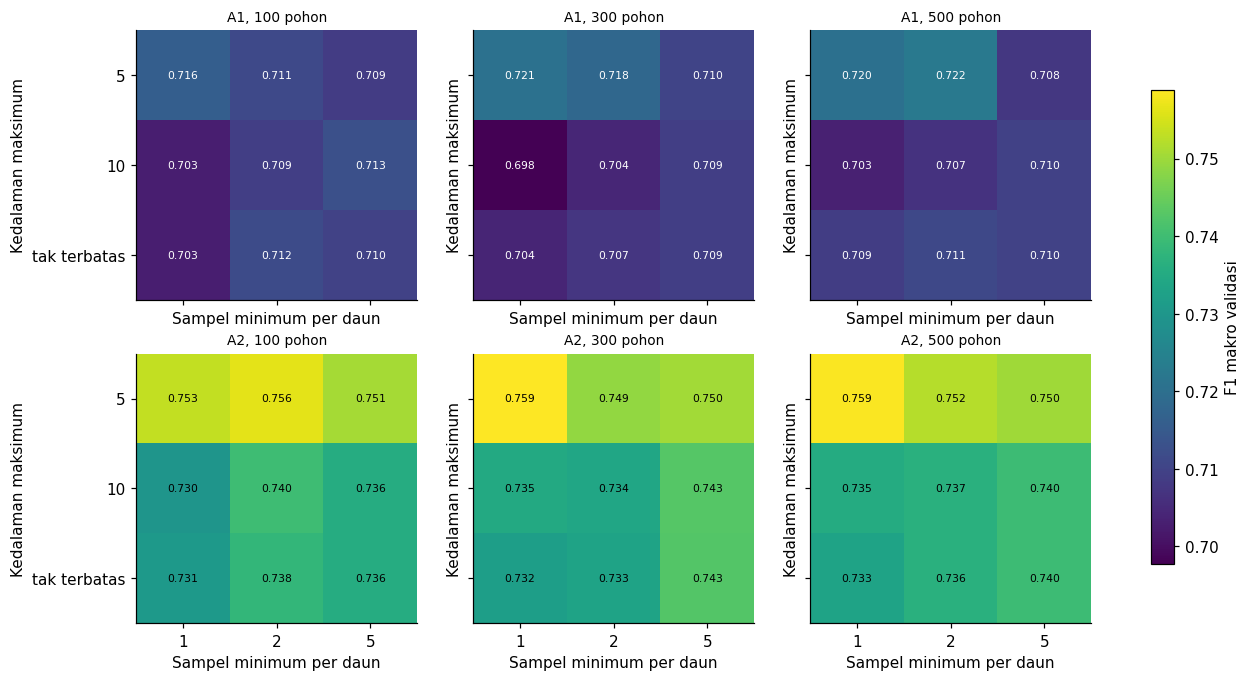

In [7]:
all_f1 = pd.concat([s["val_f1_mean"] for s in summaries.values()])
vmin, vmax = float(all_f1.min()), float(all_f1.max())
depth_order = [ev.depth_label(d) for d in MAX_DEPTH_VALUES]

fig, axes = plt.subplots(2, len(N_TREES_VALUES), figsize=(14, 7), sharex=True, sharey=True)
for row, (name, summary) in enumerate(summaries.items()):
    for col, n_trees in enumerate(N_TREES_VALUES):
        subset = summary[summary["n_estimators"] == n_trees].assign(depth_label=lambda t: t["max_depth"].map(ev.depth_label))
        pivot = subset.pivot(index="depth_label", columns="min_samples_leaf", values="val_f1_mean").reindex(depth_order)
        image = ev.plot_heatmap(axes[row, col], pivot, f"{name}, {n_trees} pohon", vmin, vmax, "Sampel minimum per daun", "Kedalaman maksimum")
fig.colorbar(image, ax=axes, shrink=0.8, label="F1 makro validasi")
save_figure(fig, "heatmap_depth_leaf.png")
plt.show()

##### 4.4 Pengaruh jumlah pohon dan perbandingan OOB dengan validasi silang

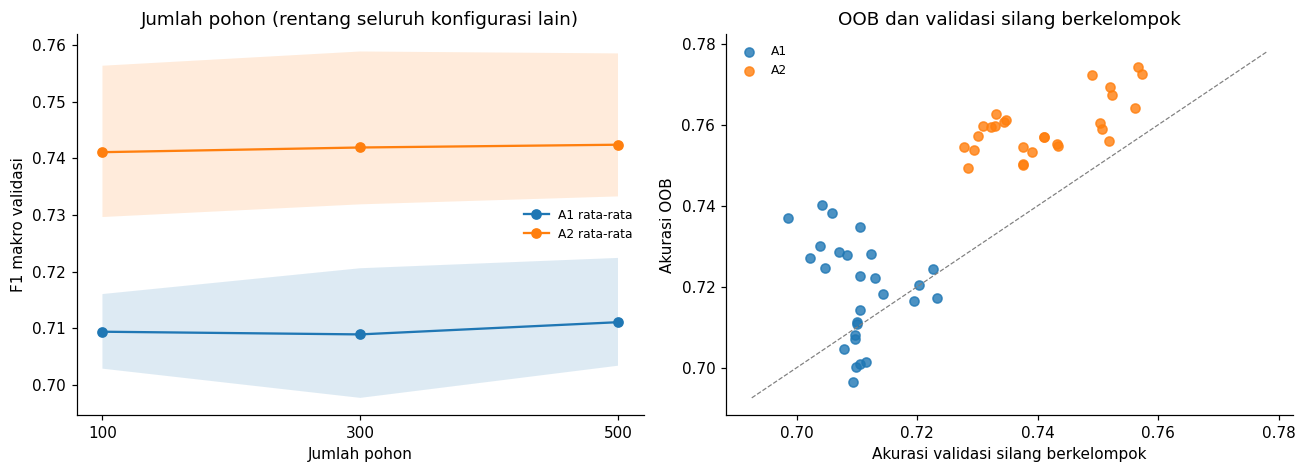

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for name, summary in summaries.items():
    grouped = summary.groupby("n_estimators")["val_f1_mean"]
    axes[0].plot(grouped.mean().index, grouped.mean().values, marker="o", label=f"{name} rata-rata")
    axes[0].fill_between(grouped.min().index, grouped.min().values, grouped.max().values, alpha=0.15)
axes[0].set(xlabel="Jumlah pohon", ylabel="F1 makro validasi", title="Jumlah pohon (rentang seluruh konfigurasi lain)")
axes[0].set_xticks(N_TREES_VALUES)
axes[0].legend(frameon=False, fontsize=8)

for name, summary in summaries.items():
    axes[1].scatter(summary["val_acc_mean"], summary["oob_accuracy_mean"], label=name, alpha=0.8)
limits = [min(axes[1].get_xlim()[0], axes[1].get_ylim()[0]), max(axes[1].get_xlim()[1], axes[1].get_ylim()[1])]
axes[1].plot(limits, limits, color="grey", linestyle="--", linewidth=0.8)
axes[1].set(xlabel="Akurasi validasi silang berkelompok", ylabel="Akurasi OOB", title="OOB dan validasi silang berkelompok")
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
save_figure(fig, "trees_and_oob.png")
plt.show()

##### 4.5 Konfigurasi terbaik dan peringkat

In [9]:
for name, summary in summaries.items():
    ranked = summary.assign(_f1=summary["val_f1_mean"].round(4), kedalaman=summary["max_depth"].map(ev.depth_label)).sort_values(["_f1", "n_estimators"], ascending=[False, True], kind="stable")
    top = ranked[["n_estimators", "kedalaman", "min_samples_leaf", "train_f1_mean", "val_f1_mean", "val_f1_sd", "oob_accuracy_mean", "fit_seconds_mean"]].head(10)
    save_table(top.round(4), f"top_configs_{name}")
    print(f"Sepuluh konfigurasi terbaik, himpunan {name}")
    display(top.round(4))

Sepuluh konfigurasi terbaik, himpunan A1


,n_estimators,kedalaman,min_samples_leaf,train_f1_mean,val_f1_mean,val_f1_sd,oob_accuracy_mean,fit_seconds_mean
config_id,,,,,,,,
19,500,5,2,0.8862,0.7225,0.0864,0.7173,0.6645
9,300,5,1,0.8957,0.7206,0.0901,0.7205,0.4148
18,500,5,1,0.8964,0.7204,0.0880,0.7243,0.6653
10,300,5,2,0.8845,0.7181,0.0863,0.7166,0.4108
0,100,5,1,0.8944,0.7161,0.0838,0.7181,0.1067
5,100,10,5,0.8738,0.7126,0.0824,0.7014,0.1204
7,100,tak terbatas,2,0.9682,0.7116,0.0855,0.7221,0.1328
1,100,5,2,0.8812,0.7113,0.0917,0.7142,0.1139
25,500,tak terbatas,2,0.9751,0.7109,0.0908,0.7280,0.5993


Sepuluh konfigurasi terbaik, himpunan A2


,n_estimators,kedalaman,min_samples_leaf,train_f1_mean,val_f1_mean,val_f1_sd,oob_accuracy_mean,fit_seconds_mean
config_id,,,,,,,,
9,300,5,1,0.9042,0.7589,0.1096,0.7725,0.2772
18,500,5,1,0.9028,0.7585,0.1108,0.7742,0.5465
1,100,5,2,0.8914,0.7564,0.1080,0.7640,0.0907
0,100,5,1,0.9010,0.7533,0.1102,0.7674,0.0922
19,500,5,2,0.8928,0.7520,0.1036,0.7694,0.5575
2,100,5,5,0.8569,0.7506,0.1009,0.7560,0.0925
11,300,5,5,0.8595,0.7503,0.0965,0.7590,0.2712
20,500,5,5,0.8603,0.7501,0.0948,0.7604,0.5257
10,300,5,2,0.8910,0.7490,0.1052,0.7723,0.2782


##### 4.6 Pemilihan konfigurasi

Pemenang adalah konfigurasi dengan rata-rata F1 makro validasi tertinggi. Jika sama pada empat desimal, dipilih hutan dengan pohon lebih sedikit. Himpunan fitur mengikuti keputusan notebook 03.

In [10]:
best_config = {name: ev.select_best(summary, "n_estimators") for name, summary in summaries.items()}
best_params = {name: ev.params_from_row(best_config[name], PARAM_COLUMNS) for name in FEATURE_SETS}

winner_table = pd.DataFrame(
    {
        name: {
            "jumlah pohon": best_params[name]["n_estimators"],
            "kedalaman": ev.depth_label(best_params[name]["max_depth"]),
            "min daun": best_params[name]["min_samples_leaf"],
            "F1 makro validasi": best_config[name]["val_f1_mean"],
            "SD": best_config[name]["val_f1_sd"],
            "F1 makro latih": best_config[name]["train_f1_mean"],
            "akurasi OOB": best_config[name]["oob_accuracy_mean"],
        }
        for name in FEATURE_SETS
    }
)
save_table(winner_table, "winner")
display(winner_table)
print("Himpunan fitur yang dievaluasi :", SELECTED_SET)
print("Parameter terpilih             :", best_params[SELECTED_SET])

,A1,A2
jumlah pohon,500,300
kedalaman,5,5
min daun,2,1
F1 makro validasi,0.722453,0.758882
SD,0.086387,0.10964
F1 makro latih,0.886197,0.904208
akurasi OOB,0.717285,0.772479


Himpunan fitur yang dievaluasi : A1
Parameter terpilih             : {'n_estimators': 500, 'max_depth': 5, 'min_samples_leaf': 2}


#### 5. Evaluasi Validasi Silang Model Terpilih

##### 5.1 Prediksi out-of-fold

In [11]:
oof = {}
for name in FEATURE_SETS:
    oof[name] = ev.cross_val_predictions(lambda n=name: make_model(best_params[n]), train, FEATURE_SETS[name])
    oof[name].to_csv(RESULTS_DIR / f"{PREFIX}_oof_{name}.csv", index=False)

oof_selected = oof[SELECTED_SET]
SELECTED_PARAMS = best_params[SELECTED_SET]
print("Himpunan fitur :", SELECTED_SET)
print("Parameter      :", SELECTED_PARAMS)
print("Baris OOF      :", len(oof_selected), f"({oof_selected['repeat'].nunique()} pengulangan)")

Himpunan fitur : A1
Parameter      : {'n_estimators': 500, 'max_depth': 5, 'min_samples_leaf': 2}
Baris OOF      : 912 (3 pengulangan)


##### 5.2 Matriks konfusi

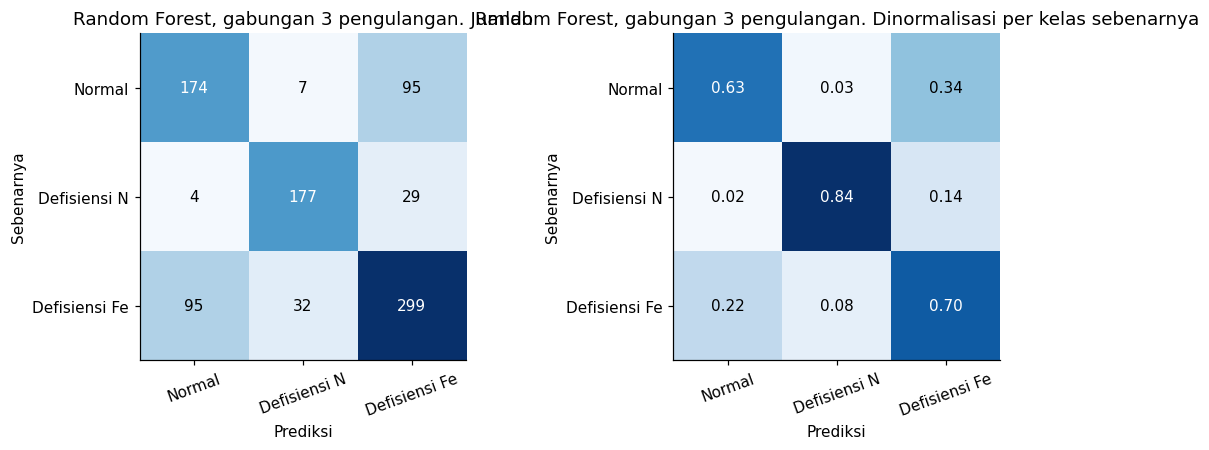

,Prediksi Normal,Prediksi Defisiensi N,Prediksi Defisiensi Fe
Sebenarnya Normal,58,2,31
Sebenarnya Defisiensi N,1,59,9
Sebenarnya Defisiensi Fe,31,10,99


In [12]:
pooled_counts = ev.confusion_counts(oof_selected["label"], oof_selected["pred"])
ev.plot_confusion(pooled_counts, title=f"{MODEL_LABEL}, gabungan 3 pengulangan.")
plt.gcf().tight_layout()
save_figure(plt.gcf(), "confusion_matrix.png")
plt.show()

confusion_table = pd.DataFrame(
    pooled_counts // oof_selected["repeat"].nunique(),
    index=[f"Sebenarnya {CLASS_LABEL_ID[c]}" for c in CLASSES],
    columns=[f"Prediksi {CLASS_LABEL_ID[c]}" for c in CLASSES],
)
save_table(confusion_table, "confusion_per_repeat")
display(confusion_table)

##### 5.3 Metrik per kelas dan skor lipatan

,precision,recall,f1,support
Normal,0.6374,0.6304,0.6339,276.0
Defisiensi N,0.8194,0.8429,0.8310,210.0
Defisiensi Fe,0.7069,0.7019,0.7044,426.0
Rata-rata makro,0.7212,0.7251,0.7231,912.0
Rata-rata berbobot,0.7117,0.7127,0.7122,912.0
Akurasi,NaN,NaN,0.7127,912.0


,mean,std,min,max
macro_f1,0.7225,0.0864,0.5703,0.9057
accuracy,0.7233,0.0812,0.6000,0.9057


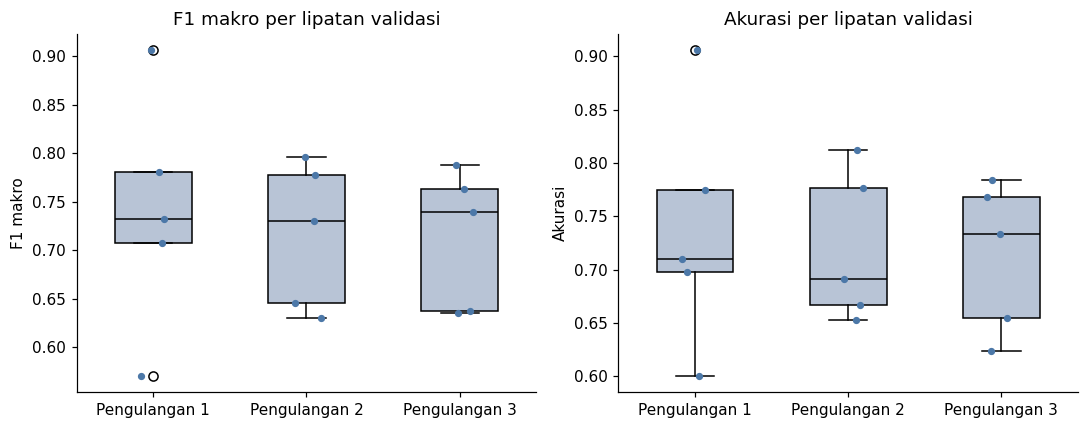

In [13]:
metric_table = ev.metrics_table(oof_selected["label"], oof_selected["pred"])
save_table(metric_table.round(4), "classification_metrics")
display(metric_table.round(4))

fold_table = ev.fold_scores(oof_selected)
fold_summary = fold_table[["macro_f1", "accuracy"]].agg(["mean", "std", "min", "max"]).T.round(4)
save_table(fold_summary, "fold_summary")
display(fold_summary)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric, title in zip(axes, ("macro_f1", "accuracy"), ("F1 makro", "Akurasi")):
    data = [fold_table.loc[fold_table["repeat"] == r, metric].to_numpy() for r in sorted(fold_table["repeat"].unique())]
    boxes = ax.boxplot(data, widths=0.5, patch_artist=True, medianprops={"color": "black"})
    for patch in boxes["boxes"]:
        patch.set_facecolor("#B8C4D6")
    for i, values in enumerate(data, start=1):
        ax.scatter(np.full(len(values), i) + rng.uniform(-0.1, 0.1, len(values)), values, s=14, color="#4C78A8", zorder=3)
    ax.set_xticks(range(1, len(data) + 1), [f"Pengulangan {r}" for r in sorted(fold_table["repeat"].unique())])
    ax.set_ylabel(title)
    ax.set_title(f"{title} per lipatan validasi")
fig.tight_layout()
save_figure(fig, "fold_scores.png")
plt.show()

##### 5.4 Kurva ROC dan Precision-Recall

$$
\mathrm{TPR} = \frac{TP}{TP + FN}, \qquad \mathrm{FPR} = \frac{FP}{FP + TN}, \qquad \mathrm{AP} = \sum_{n} (R_n - R_{n-1})\, P_n
$$

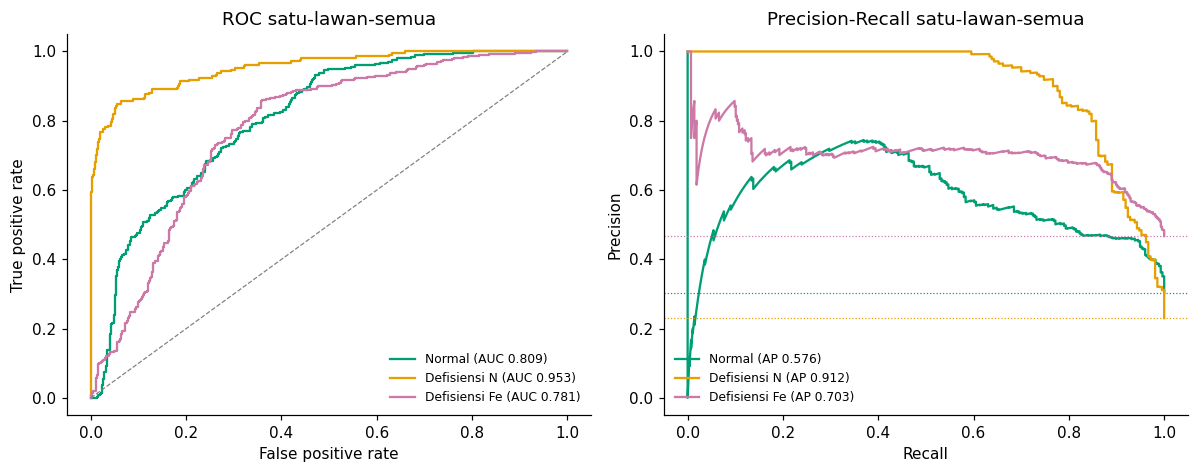

,AUC,AP,prevalensi
Normal,0.8086,0.5762,0.3026
Defisiensi N,0.9534,0.9116,0.2303
Defisiensi Fe,0.7807,0.7027,0.4671
Rata-rata makro,0.8476,0.7301,0.3333


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
curves = ev.plot_roc_pr(oof_selected, axes)
fig.tight_layout()
save_figure(fig, "roc_pr.png")
plt.show()

curve_table = pd.DataFrame({CLASS_LABEL_ID[k]: {"AUC": v["auc"], "AP": v["ap"], "prevalensi": v["prevalence"]} for k, v in curves.items()}).T
curve_table.loc["Rata-rata makro"] = curve_table.mean()
save_table(curve_table.round(4), "roc_pr_summary")
display(curve_table.round(4))

##### 5.5 Kurva pembelajaran

,train_files,train_f1,train_sd,val_f1,val_sd
fraction,,,,,
0.2,61.0,0.9582,0.0419,0.6584,0.1314
0.4,108.4,0.9040,0.0345,0.6697,0.1362
0.6,153.6,0.9188,0.0201,0.7205,0.1244
0.8,197.8,0.9008,0.0216,0.7043,0.0941
1.0,243.2,0.8848,0.0145,0.7391,0.1215


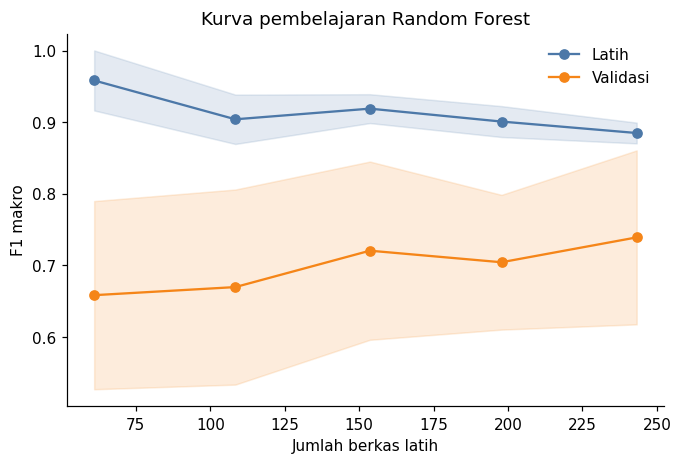

In [15]:
learning = ev.learning_curve(lambda: make_model(SELECTED_PARAMS), train, SELECTED_FEATURES, fractions=LEARNING_FRACTIONS, seed=SEED)
learning_summary = learning.groupby("fraction").agg(
    train_files=("train_files", "mean"),
    train_f1=("train_macro_f1", "mean"), train_sd=("train_macro_f1", "std"),
    val_f1=("val_macro_f1", "mean"), val_sd=("val_macro_f1", "std"),
)
save_table(learning_summary.round(4), "learning_curve")
display(learning_summary.round(4))

fig, ax = plt.subplots(figsize=(7, 4.4))
for column, sd, label, color in (("train_f1", "train_sd", "Latih", "#4C78A8"), ("val_f1", "val_sd", "Validasi", "#F58518")):
    ax.plot(learning_summary["train_files"], learning_summary[column], marker="o", color=color, label=label)
    ax.fill_between(learning_summary["train_files"], learning_summary[column] - learning_summary[sd], learning_summary[column] + learning_summary[sd], color=color, alpha=0.15)
ax.set(xlabel="Jumlah berkas latih", ylabel="F1 makro", title=f"Kurva pembelajaran {MODEL_LABEL}")
ax.legend(frameon=False)
save_figure(fig, "learning_curve.png")
plt.show()

##### 5.6 Pentingnya fitur (permutasi)

$$
\mathrm{PI}_j = F1_{\text{dasar}} - \frac{1}{R}\sum_{r=1}^{R} F1_{\text{acak}}^{(j, r)}
$$

,importance_mean,importance_sd
feature,,
Mean_R,0.3987,0.1269
Mean_G,0.0758,0.0661
Mean_B,0.0985,0.0457


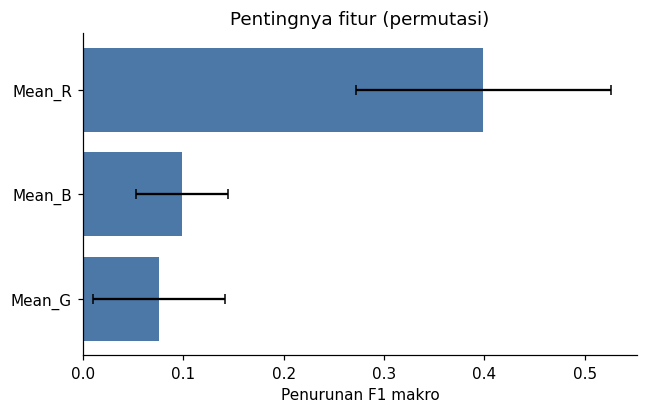

In [16]:
importance = ev.permutation_importance(lambda: make_model(SELECTED_PARAMS), train, SELECTED_FEATURES, n_repeats=PERMUTATION_REPEATS, seed=SEED)
save_table(importance.round(4), "permutation_importance")
display(importance.round(4))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ordered = importance.sort_values("importance_mean")
ax.barh(ordered.index, ordered["importance_mean"], xerr=ordered["importance_sd"], color="#4C78A8", capsize=3)
ax.set(xlabel="Penurunan F1 makro", title="Pentingnya fitur (permutasi)")
save_figure(fig, "permutation_importance.png")
plt.show()

##### 5.7 Galeri salah klasifikasi

,label,pred,jumlah
0,Defisiensi Fe,Defisiensi N,11
1,Defisiensi Fe,Normal,29
2,Defisiensi N,Defisiensi Fe,8
3,Defisiensi N,Normal,2
4,Normal,Defisiensi Fe,30
5,Normal,Defisiensi N,2


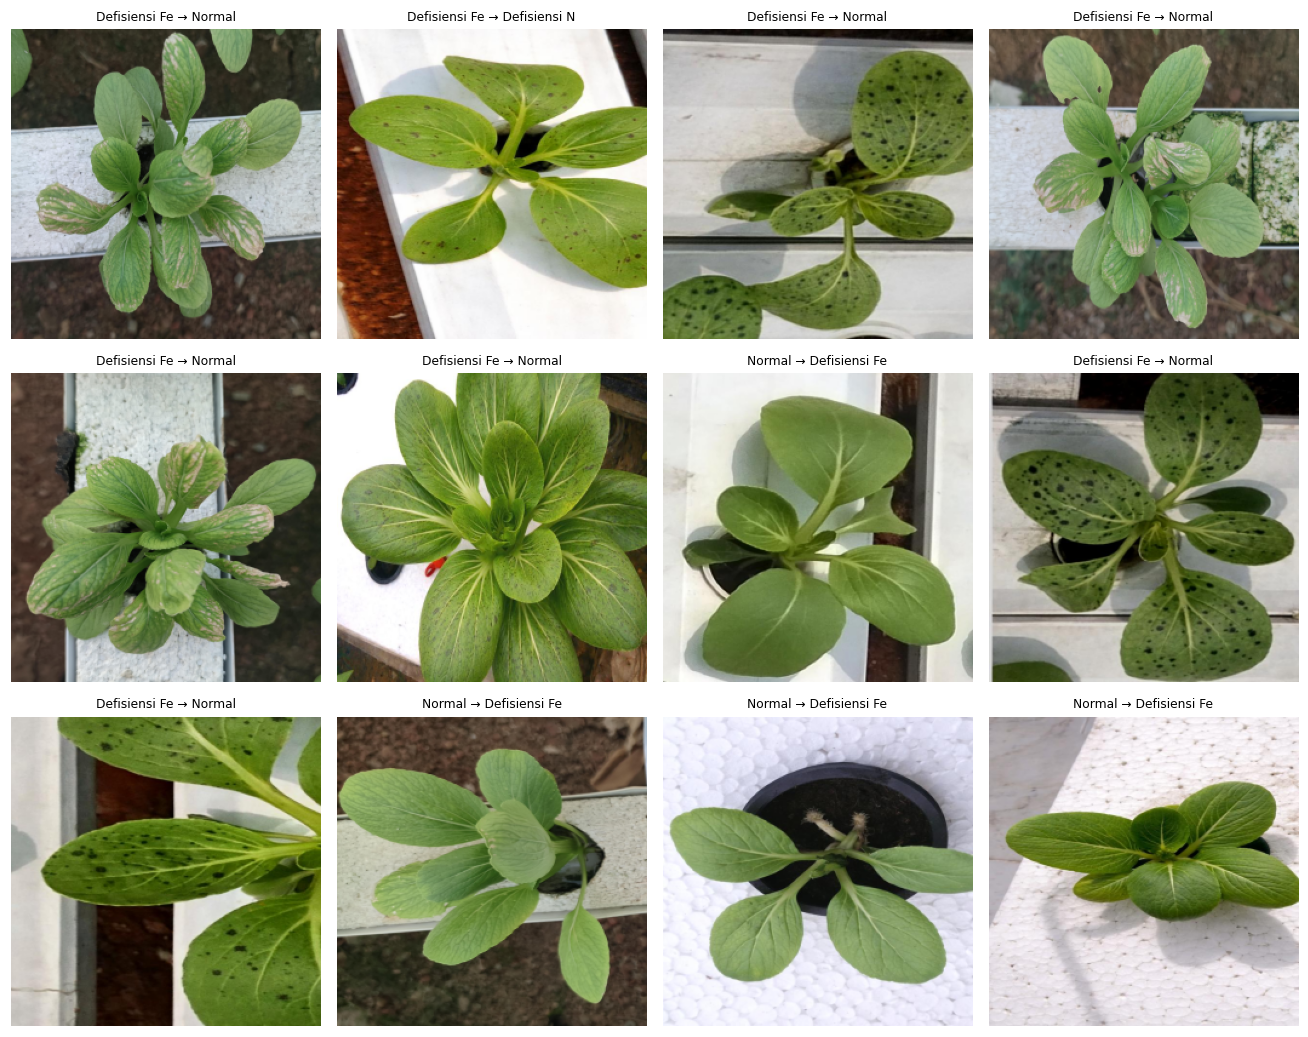

In [17]:
oof_selected = oof_selected.assign(correct=oof_selected["label"] == oof_selected["pred"])
errors = oof_selected[(oof_selected["repeat"] == 1) & (~oof_selected["correct"])]
error_pairs = errors.groupby(["label", "pred"]).size().rename("jumlah").reset_index()
error_pairs["label"] = error_pairs["label"].map(CLASS_LABEL_ID)
error_pairs["pred"] = error_pairs["pred"].map(CLASS_LABEL_ID)
save_table(error_pairs, "misclassified_pairs", index=False)
display(error_pairs)

fig = ev.plot_gallery(errors, RAW_DIR, max_items=GALLERY_SIZE, seed=SEED)
save_figure(fig, "misclassified_gallery.png")
plt.show()

##### 5.8 Interval kepercayaan bootstrap (resampling foto sumber)

$$
\hat{\theta}^{*(b)} = \theta\left(\{g_1^{*}, \dots, g_G^{*}\}\right), \qquad g_i^{*} \sim \mathrm{Uniform}(\mathcal{G}), \qquad \mathrm{CI}_{95\%} = \left[\hat{\theta}^{*}_{0{,}025},\ \hat{\theta}^{*}_{0{,}975}\right]
$$

,estimate,low,high
F1 makro,0.7231,0.6462,0.7821
Akurasi,0.7127,0.6461,0.7790
Recall Defisiensi N,0.8429,0.6415,0.9828
Recall Defisiensi Fe,0.7019,0.6250,0.7786
Recall Normal,0.6304,0.5168,0.7568


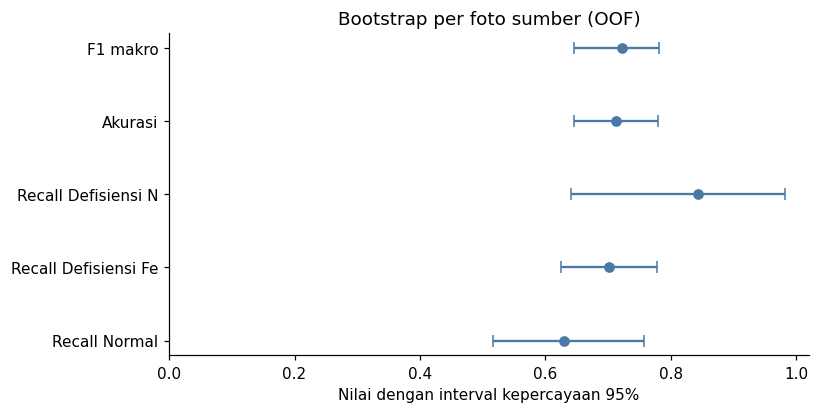

In [18]:
bootstrap_metrics = {
    "F1 makro": ev.fast_macro_f1,
    "Akurasi": ev.fast_accuracy,
    "Recall Defisiensi N": ev.fast_recall("n_deficiency"),
    "Recall Defisiensi Fe": ev.fast_recall("fe_deficiency"),
    "Recall Normal": ev.fast_recall("normal"),
}
bootstrap_rows = {name: ev.bootstrap_group_ci(oof_selected, metric, n_boot=N_BOOTSTRAP, seed=SEED) for name, metric in bootstrap_metrics.items()}
bootstrap_table = pd.DataFrame(bootstrap_rows).T[["estimate", "low", "high"]]
save_table(bootstrap_table.round(4), "bootstrap_ci")
display(bootstrap_table.round(4))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
y_positions = np.arange(len(bootstrap_table))[::-1]
ax.errorbar(bootstrap_table["estimate"], y_positions, xerr=[bootstrap_table["estimate"] - bootstrap_table["low"], bootstrap_table["high"] - bootstrap_table["estimate"]], fmt="o", color="#4C78A8", capsize=4)
ax.set_yticks(y_positions, bootstrap_table.index)
ax.set(xlabel="Nilai dengan interval kepercayaan 95%", title="Bootstrap per foto sumber (OOF)")
ax.set_xlim(0, 1.02)
save_figure(fig, "bootstrap_ci.png")
plt.show()

##### 5.9 Perbandingan himpunan fitur A1 dan A2

In [19]:
comparison_rows = {}
for name in FEATURE_SETS:
    part = oof[name]
    folds = ev.fold_scores(part)
    comparison_rows[name] = {
        "parameter": str(best_params[name]),
        "F1 makro (rata-rata lipatan)": folds["macro_f1"].mean(),
        "SD lipatan": folds["macro_f1"].std(),
        "akurasi": folds["accuracy"].mean(),
        "recall Normal": ev.fast_recall("normal")(part["label"], part["pred"]),
        "recall Defisiensi N": ev.fast_recall("n_deficiency")(part["label"], part["pred"]),
        "recall Defisiensi Fe": ev.fast_recall("fe_deficiency")(part["label"], part["pred"]),
    }
feature_set_comparison = pd.DataFrame(comparison_rows)
save_table(feature_set_comparison, "feature_set_comparison")
display(feature_set_comparison)

,A1,A2
parameter,"{'n_estimators': 500, 'max_depth': 5, 'min_sam...","{'n_estimators': 300, 'max_depth': 5, 'min_sam..."
F1 makro (rata-rata lipatan),0.722453,0.758882
SD lipatan,0.086387,0.10964
akurasi,0.723321,0.757368
recall Normal,0.630435,0.699275
recall Defisiensi N,0.842857,0.82381
recall Defisiensi Fe,0.701878,0.741784


#### 6. Analisis Khusus Random Forest

##### 6.1 Galat OOB terhadap jumlah pohon

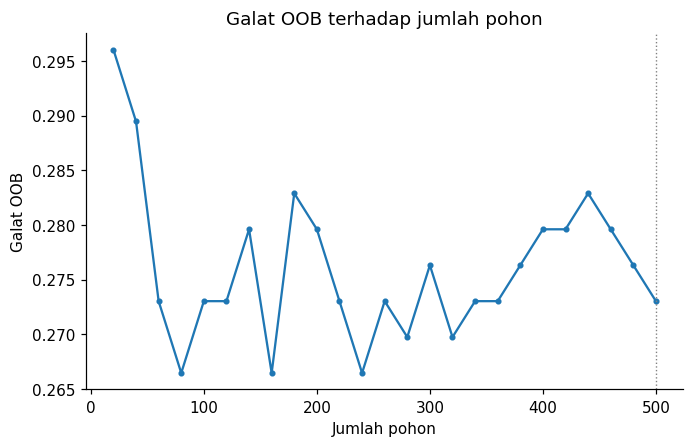

,galat_oob
pohon,
20,0.2961
260,0.2730
500,0.2730


In [20]:
X_full = train[SELECTED_FEATURES].to_numpy(dtype=float)
y_full = train["label"].to_numpy()

oob_rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    growing = models.build_random_forest(n_estimators=OOB_TREE_STEP, oob_score=True, **{k: v for k, v in SELECTED_PARAMS.items() if k != "n_estimators"})
    growing.set_params(warm_start=True)
    for n_trees in range(OOB_TREE_STEP, OOB_TREE_MAX + 1, OOB_TREE_STEP):
        growing.set_params(n_estimators=n_trees)
        growing.fit(X_full, y_full)
        oob_rows.append({"pohon": n_trees, "galat_oob": 1.0 - growing.oob_score_})
oob_curve = pd.DataFrame(oob_rows).set_index("pohon")
save_table(oob_curve.round(4), "oob_curve")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(oob_curve.index, oob_curve["galat_oob"], marker="o", markersize=3)
ax.axvline(SELECTED_PARAMS["n_estimators"], color="grey", linestyle=":", linewidth=0.9)
ax.set(xlabel="Jumlah pohon", ylabel="Galat OOB", title="Galat OOB terhadap jumlah pohon")
save_figure(fig, "oob_curve.png")
plt.show()
display(oob_curve.iloc[[0, len(oob_curve) // 2, -1]].round(4))

##### 6.2 Pentingnya fitur: impuritas dan permutasi

,MDI,SD antar pohon,permutasi,SD permutasi
Mean_R,0.4814,0.2093,0.3987,0.1269
Mean_G,0.3340,0.1927,0.0758,0.0661
Mean_B,0.1846,0.0737,0.0985,0.0457


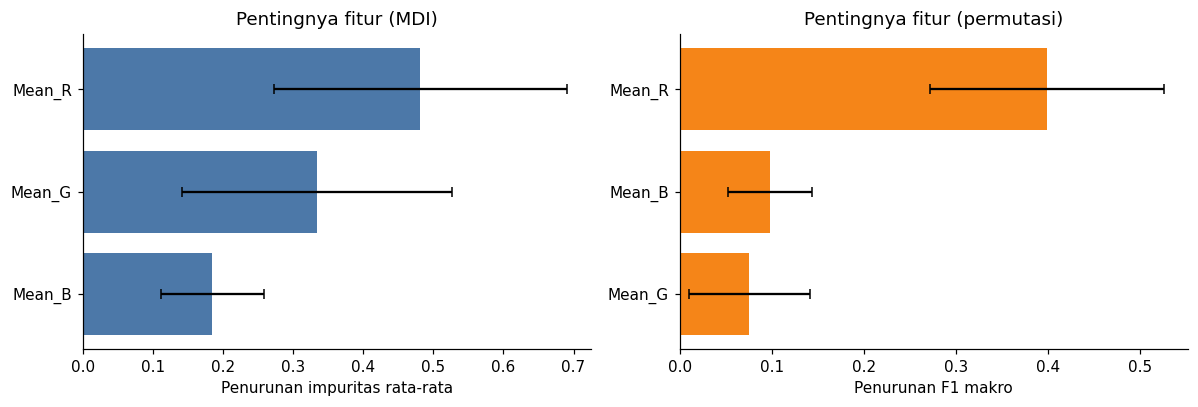

In [21]:
forest_model = make_model(SELECTED_PARAMS).fit(X_full, y_full, SELECTED_FEATURES, CLASSES)
forest = forest_model.estimator
per_tree = np.array([tree.feature_importances_ for tree in forest.estimators_])
mdi_table = pd.DataFrame({"MDI": forest.feature_importances_, "SD antar pohon": per_tree.std(axis=0, ddof=1)}, index=SELECTED_FEATURES)
importance_compare = mdi_table.join(importance.rename(columns={"importance_mean": "permutasi", "importance_sd": "SD permutasi"}))
save_table(importance_compare.round(4), "importance_comparison")
display(importance_compare.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ordered = mdi_table.sort_values("MDI")
axes[0].barh(ordered.index, ordered["MDI"], xerr=ordered["SD antar pohon"], color="#4C78A8", capsize=3)
axes[0].set(xlabel="Penurunan impuritas rata-rata", title="Pentingnya fitur (MDI)")
ordered = importance.sort_values("importance_mean")
axes[1].barh(ordered.index, ordered["importance_mean"], xerr=ordered["importance_sd"], color="#F58518", capsize=3)
axes[1].set(xlabel="Penurunan F1 makro", title="Pentingnya fitur (permutasi)")
fig.tight_layout()
save_figure(fig, "importance_comparison.png")
plt.show()

##### 6.3 Kedalaman dan jumlah daun pohon dalam hutan

,kedalaman,jumlah daun
count,500.0,500.000
mean,5.0,20.936
std,0.0,3.217
min,5.0,9.000
25%,5.0,19.000
50%,5.0,21.000
75%,5.0,23.000
max,5.0,30.000


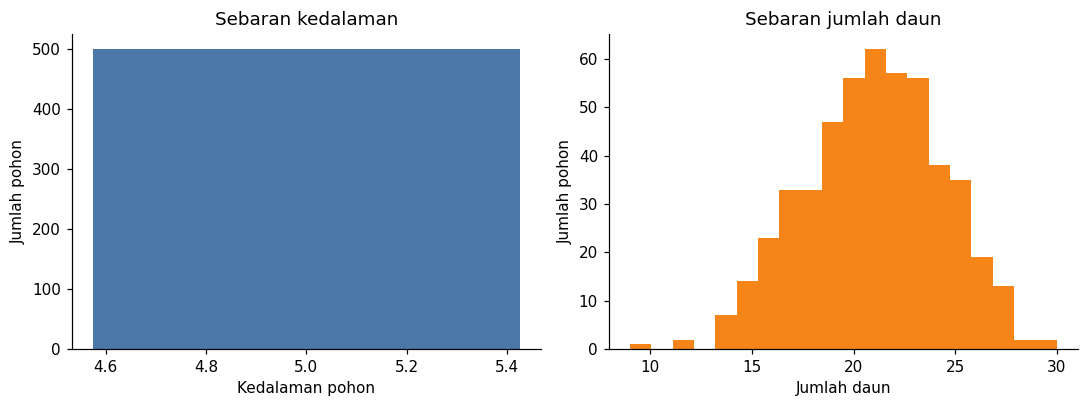

In [22]:
depths = np.array([tree.get_depth() for tree in forest.estimators_])
leaves = np.array([tree.get_n_leaves() for tree in forest.estimators_])
tree_stats = pd.DataFrame({"kedalaman": pd.Series(depths).describe(), "jumlah daun": pd.Series(leaves).describe()}).round(3)
save_table(tree_stats, "tree_statistics")
display(tree_stats)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(depths, bins=range(int(depths.min()), int(depths.max()) + 2), color="#4C78A8", align="left", rwidth=0.85)
axes[0].set(xlabel="Kedalaman pohon", ylabel="Jumlah pohon", title="Sebaran kedalaman")
axes[1].hist(leaves, bins=20, color="#F58518")
axes[1].set(xlabel="Jumlah daun", ylabel="Jumlah pohon", title="Sebaran jumlah daun")
fig.tight_layout()
save_figure(fig, "tree_depth_leaves.png")
plt.show()

##### 6.4 Wilayah keputusan dua dimensi

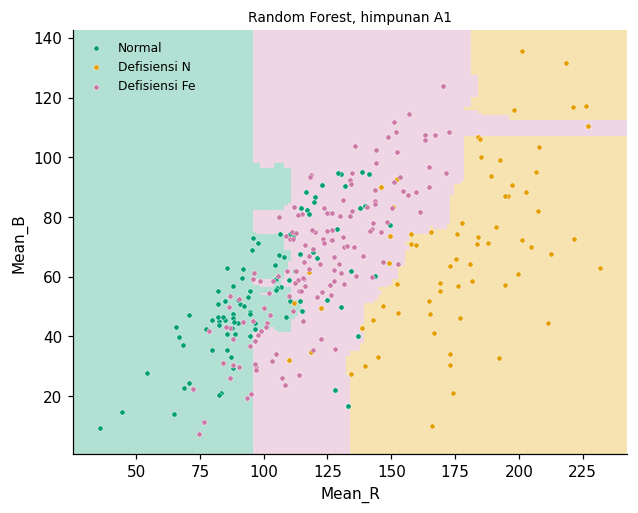

In [23]:
pair = ev.top_feature_pair(importance)
fig, ax = plt.subplots(figsize=(6.5, 5))
ev.plot_decision_regions(forest_model, train, SELECTED_FEATURES, pair, ax, title=f"Random Forest, himpunan {SELECTED_SET}")
ax.legend(frameon=False, fontsize=8)
save_figure(fig, "decision_regions.png")
plt.show()

##### 6.5 Ringkasan khusus Random Forest

In [24]:
MODEL_SPECIFIC = {
    "oob_error_final": float(oob_curve["galat_oob"].iloc[-1]),
    "oob_accuracy_best_config": {name: as_float(best_config[name]["oob_accuracy_mean"]) for name in FEATURE_SETS},
    "mdi_importance": {k: float(v) for k, v in mdi_table["MDI"].items()},
    "tree_depth": {"mean": float(depths.mean()), "min": int(depths.min()), "max": int(depths.max())},
    "tree_leaves": {"mean": float(leaves.mean()), "min": int(leaves.min()), "max": int(leaves.max())},
    "decision_region_features": list(pair),
}
print(json.dumps(MODEL_SPECIFIC["tree_depth"], indent=2))

{
  "mean": 5.0,
  "min": 5,
  "max": 5
}


#### 7. Model Akhir dan Waktu Komputasi

##### 7.1 Pelatihan pada seluruh data latih

In [25]:
X_selected = train[SELECTED_FEATURES].to_numpy(dtype=float)
y_selected = train["label"].to_numpy()

final_model = make_model(SELECTED_PARAMS).fit(X_selected, y_selected, SELECTED_FEATURES, CLASSES)
train_pred = final_model.predict(X_selected)

print("Parameter      :", SELECTED_PARAMS)
print("F1 makro latih :", round(ev.macro_f1(y_selected, train_pred), 4))
print("Akurasi latih  :", round(float(np.mean(train_pred == y_selected)), 4))

Parameter      : {'n_estimators': 500, 'max_depth': 5, 'min_samples_leaf': 2}
F1 makro latih : 0.8685
Akurasi latih  : 0.8618


##### 7.2 Waktu komputasi

In [26]:
preprocessing_timing = pd.read_csv(TABLES_DIR / "01_timing_per_stage.csv", index_col=0)
PREPROCESSING_MS = float(preprocessing_timing.loc["total (tanpa baca berkas)", "rata-rata (ms)"])
PREPROCESSING_SD_MS = float(preprocessing_timing.loc["total (tanpa baca berkas)", "simpangan baku (ms)"])

fit_timing = ev.time_calls(lambda: make_model(SELECTED_PARAMS).fit(X_selected, y_selected, SELECTED_FEATURES, CLASSES), repeats=TRAIN_TIMING_REPEATS)
sample_rows = [X_selected[i : i + 1] for i in range(len(X_selected))]
predict_timing = ev.time_single_predictions(lambda i: final_model.predict(sample_rows[i]), len(X_selected), repeats=PREDICT_TIMING_REPEATS)

timing_rows = [
    {"pengukuran": "Praproses per citra", "nilai": PREPROCESSING_MS, "simpangan_baku": PREPROCESSING_SD_MS, "satuan": "ms"},
    {"pengukuran": "Pelatihan model akhir", "nilai": fit_timing["mean"], "simpangan_baku": fit_timing["sd"], "satuan": "detik"},
]
for name, seconds in tuning_seconds.items():
    timing_rows.append({"pengukuran": f"Penalaan {name} ({len(grid)} konfigurasi x 15 lipatan)", "nilai": seconds, "simpangan_baku": np.nan, "satuan": "detik"})
timing_rows.append({"pengukuran": "Prediksi per sampel", "nilai": predict_timing["mean_ms"], "simpangan_baku": predict_timing["sd_ms"], "satuan": "ms"})
timing_table = pd.DataFrame(timing_rows).set_index("pengukuran")
save_table(timing_table.round(4), "compute_time")
display(timing_table.round(4))

,nilai,simpangan_baku,satuan
pengukuran,,,
Praproses per citra,7.9350,6.1550,ms
Pelatihan model akhir,0.3939,0.0219,detik
Penalaan A1 (27 konfigurasi x 15 lipatan),161.7308,NaN,detik
Penalaan A2 (27 konfigurasi x 15 lipatan),132.6602,NaN,detik
Prediksi per sampel,8.3672,0.3076,ms


#### 8. Penyimpanan Hasil

##### 8.1 Berkas hasil dan model

In [27]:
artifact_path = MODELS_DIR / f"{PREFIX}_candidate.joblib"
joblib.dump(final_model.estimator, artifact_path)

results = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "model": PREFIX,
    "seed": SEED,
    "libraries": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
    "hardware": HARDWARE,
    "data": {"train_rows": int(len(train)), "train_groups": int(train["source_group"].nunique()), "fold_columns": list(ev.FOLD_COLUMNS)},
    "grid": {"configurations": int(len(grid))},
    "feature_set": {"selected": SELECTED_SET, "features": SELECTED_FEATURES, "source": "03_c45_results.json"},
    "best_config": {
        name: {
            "params": best_params[name],
            "val_macro_f1_mean": as_float(best_config[name]["val_f1_mean"]),
            "val_macro_f1_sd": as_float(best_config[name]["val_f1_sd"]),
            "train_macro_f1_mean": as_float(best_config[name]["train_f1_mean"]),
        }
        for name in FEATURE_SETS
    },
    "selected": {
        "feature_set": SELECTED_SET,
        "params": SELECTED_PARAMS,
        "oof_metrics": {
            "macro_f1_fold_mean": float(fold_table["macro_f1"].mean()),
            "macro_f1_fold_sd": float(fold_table["macro_f1"].std()),
            "accuracy_fold_mean": float(fold_table["accuracy"].mean()),
            "per_class_recall": {c: float(ev.fast_recall(c)(oof_selected["label"], oof_selected["pred"])) for c in CLASSES},
        },
        "bootstrap_95ci": {name: {k: float(v) for k, v in row.items() if k in ("estimate", "low", "high")} for name, row in bootstrap_rows.items()},
    },
    "model_specific": MODEL_SPECIFIC,
    "compute": {
        "preprocessing_ms_per_image": {"mean": PREPROCESSING_MS, "sd": PREPROCESSING_SD_MS},
        "final_train_seconds": fit_timing,
        "tuning_seconds": tuning_seconds,
        "predict_ms_per_sample": predict_timing,
    },
    "artifacts": {"model": str(artifact_path.relative_to(ML_DIR)), "oof": [f"reports/results/{PREFIX}_oof_{name}.csv" for name in FEATURE_SETS]},
}
results_path = RESULTS_DIR / f"{PREFIX}_results.json"
results_path.write_text(json.dumps(results, indent=2, default=str), encoding="utf-8")
print("Disimpan :", results_path)
print("Disimpan :", artifact_path, f"({artifact_path.stat().st_size} byte)")

Disimpan : D:\LARAGON\www\nutrify\ml\reports\results\06_random_forest_results.json
Disimpan : D:\LARAGON\www\nutrify\ml\models\candidates\06_random_forest_candidate.joblib (2004049 byte)


##### 8.2 Ringkasan akhir

In [28]:
final_summary = pd.DataFrame(
    [
        ("Himpunan fitur", SELECTED_SET),
        ("Parameter", str(SELECTED_PARAMS)),
        ("F1 makro validasi (rata-rata 15 lipatan)", round(results["selected"]["oof_metrics"]["macro_f1_fold_mean"], 4)),
        ("SD F1 makro lipatan", round(results["selected"]["oof_metrics"]["macro_f1_fold_sd"], 4)),
        ("Recall Normal", round(results["selected"]["oof_metrics"]["per_class_recall"]["normal"], 4)),
        ("Recall Defisiensi N", round(results["selected"]["oof_metrics"]["per_class_recall"]["n_deficiency"], 4)),
        ("Recall Defisiensi Fe", round(results["selected"]["oof_metrics"]["per_class_recall"]["fe_deficiency"], 4)),
        ("Prediksi per sampel (ms)", round(predict_timing["mean_ms"], 4)),
    ],
    columns=["item", "nilai"],
)
save_table(final_summary, "final_summary", index=False)
display(final_summary)

,item,nilai
0,Himpunan fitur,A1
1,Parameter,"{'n_estimators': 500, 'max_depth': 5, 'min_sam..."
2,F1 makro validasi (rata-rata 15 lipatan),0.7225
3,SD F1 makro lipatan,0.0864
4,Recall Normal,0.6304
5,Recall Defisiensi N,0.8429
6,Recall Defisiensi Fe,0.7019
7,Prediksi per sampel (ms),8.3672
